In [82]:
#%pip install matplotlib

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [84]:
df = pd.read_csv('customer_churn_exam_dataset_3500.csv')

In [85]:
df.head(20)

,CustomerID,Age,Gender,Region,PlanType,MonthlyCharges,TenureMonths,SupportTickets,AvgMonthlyUsageHours,ContractType,PaymentMethod,AutoPay,SatisfactionScore,LastLoginDays,ReferralCount,DeviceCount,Churn
0,C0001,__35__,Male,South,Basic,16.62,2,5,__27.0__,Quarterly,Card,Yes,4,26,0,1,0
1,C0002,26,Male,North,Standard,46.23,__4__,0,46.1,Monthly,UPI,Yes,5,11,0,2,1
2,C0003,31,Female,North,Standard,43.04,32,0,27.2,NaN,UPI,Yes,7,6,2,3,0
3,C0004,34,Male,East,Basic,29.19,20,4,25.1,Monthly,Bank Transfer,Yes,4,19,0,4,0
4,C0005,38,Female,North,Basic,24.95,1,4,49.0,Monthly,Cash,No,3,25,0,3,1
5,C0006,36,Female,East,Standard,47.99,11,0,36.8,3,Card,Yes,8,0,2,3,0
6,C0007,28,Female,West,Standard,37.51,64,2,40.2,Quarterly,NaN,Yes,5,10,2,3,0
7,C0008,58,Male,Central,Standard,37.32,13,4,50.6,3,Bank Transfer,Yes,5,13,4,2,0
8,C0009,26,Male,East,Premium,69.6,33,1,57.3,Yearly,Cash,Yes,6,1,2,2,0
9,C0010,23,Male,Central,Standard,43.56,5,0,37.6,Monthly,Card,No,5,0,0,2,0


here Custorem id has to be dropped cuz we can use the index number
many datas are in double dashes, gotta fix those
and most of then are in strings. many need to be in floot or int (before encoding i guess)
handle nan values
visualise
encode

In [86]:
df.shape

(3500, 17)

In [87]:
df.isna().sum()

CustomerID               0
Age                     53
Gender                  55
Region                  33
PlanType                43
MonthlyCharges          76
TenureMonths            39
SupportTickets          43
AvgMonthlyUsageHours    73
ContractType            47
PaymentMethod           39
AutoPay                 44
SatisfactionScore       57
LastLoginDays           28
ReferralCount           19
DeviceCount             24
Churn                    0
dtype: int64

In [88]:
df.dtypes

CustomerID                str
Age                       str
Gender                    str
Region                    str
PlanType                  str
MonthlyCharges            str
TenureMonths              str
SupportTickets            str
AvgMonthlyUsageHours      str
ContractType              str
PaymentMethod             str
AutoPay                   str
SatisfactionScore         str
LastLoginDays             str
ReferralCount             str
DeviceCount               str
Churn                   int64
dtype: object

In [89]:
df.head(1)

,CustomerID,Age,Gender,Region,PlanType,MonthlyCharges,TenureMonths,SupportTickets,AvgMonthlyUsageHours,ContractType,PaymentMethod,AutoPay,SatisfactionScore,LastLoginDays,ReferralCount,DeviceCount,Churn
0,C0001,__35__,Male,South,Basic,16.62,2,5,__27.0__,Quarterly,Card,Yes,4,26,0,1,0


In [90]:
df = df.drop("CustomerID", axis = 1)

In [91]:
df = df.map(lambda x: x.strip('__') if isinstance(x,str) else x)

In [92]:
df.head(2)

,Age,Gender,Region,PlanType,MonthlyCharges,TenureMonths,SupportTickets,AvgMonthlyUsageHours,ContractType,PaymentMethod,AutoPay,SatisfactionScore,LastLoginDays,ReferralCount,DeviceCount,Churn
0,35,Male,South,Basic,16.62,2,5,27.0,Quarterly,Card,Yes,4,26,0,1,0
1,26,Male,North,Standard,46.23,4,0,46.1,Monthly,UPI,Yes,5,11,0,2,1


In [93]:
#df.isna().sum()

In [94]:
num_cols = ['Age', 'TenureMonths', 'MonthlyCharges', 'SupportTickets', 'AvgMonthlyUsageHours', 'SatisfactionScore','LastLoginDays', 'ReferralCount', 'DeviceCount' ]
for col in num_cols:
    df[col]= pd.to_numeric(df[col], errors='coerce')

fillna_mean_target = ['TenureMonths', 'Age', 'SupportTickets', 'AvgMonthlyUsageHours', 'SatisfactionScore', 'ReferralCount', 'DeviceCount' ]
df[fillna_mean_target] = df[fillna_mean_target].fillna(df[fillna_mean_target].mean())   

fillna_median = ['MonthlyCharges', 'LastLoginDays',]
df[fillna_median] = df[fillna_median].fillna(df[fillna_median].median())

In [95]:
df.isna().sum()

Age                      0
Gender                  55
Region                  33
PlanType                43
MonthlyCharges           0
TenureMonths             0
SupportTickets           0
AvgMonthlyUsageHours     0
ContractType            47
PaymentMethod           39
AutoPay                 44
SatisfactionScore        0
LastLoginDays            0
ReferralCount            0
DeviceCount              0
Churn                    0
dtype: int64

## filling str values with mode

In [96]:
str_col_mode = ['Gender','Region','PlanType','ContractType','PaymentMethod','AutoPay']
df[str_col_mode] = df[str_col_mode].fillna(df[str_col_mode].mode().iloc[0])

In [97]:
df.isna().sum()

Age                     0
Gender                  0
Region                  0
PlanType                0
MonthlyCharges          0
TenureMonths            0
SupportTickets          0
AvgMonthlyUsageHours    0
ContractType            0
PaymentMethod           0
AutoPay                 0
SatisfactionScore       0
LastLoginDays           0
ReferralCount           0
DeviceCount             0
Churn                   0
dtype: int64

visualise before encoding

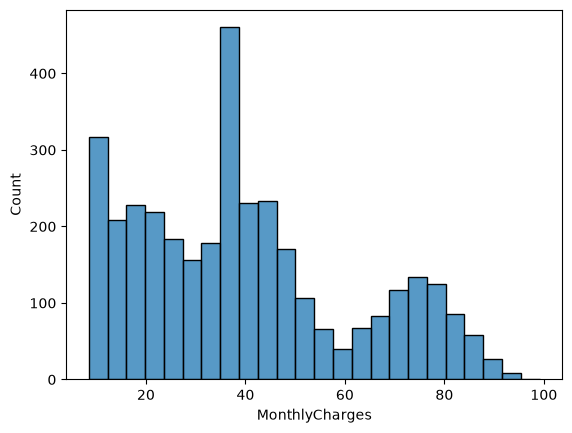

In [101]:
#plt.figure(figsize=(8,5))
sns.histplot(data=df, x='MonthlyCharges')
plt.show()

C:\Users\Ebteshamul\AppData\Local\Temp\ipykernel_5508\2015222970.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='ContractType', ax=axes[0, 1], palette='Set2')
C:\Users\Ebteshamul\AppData\Local\Temp\ipykernel_5508\2015222970.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='TenureMonths', ax=axes[1, 0], palette='Pastel1')
C:\Users\Ebteshamul\AppData\Local\Temp\ipykernel_5508\2015222970.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='PlanType', ax=axes[1, 1], palette='Set3')


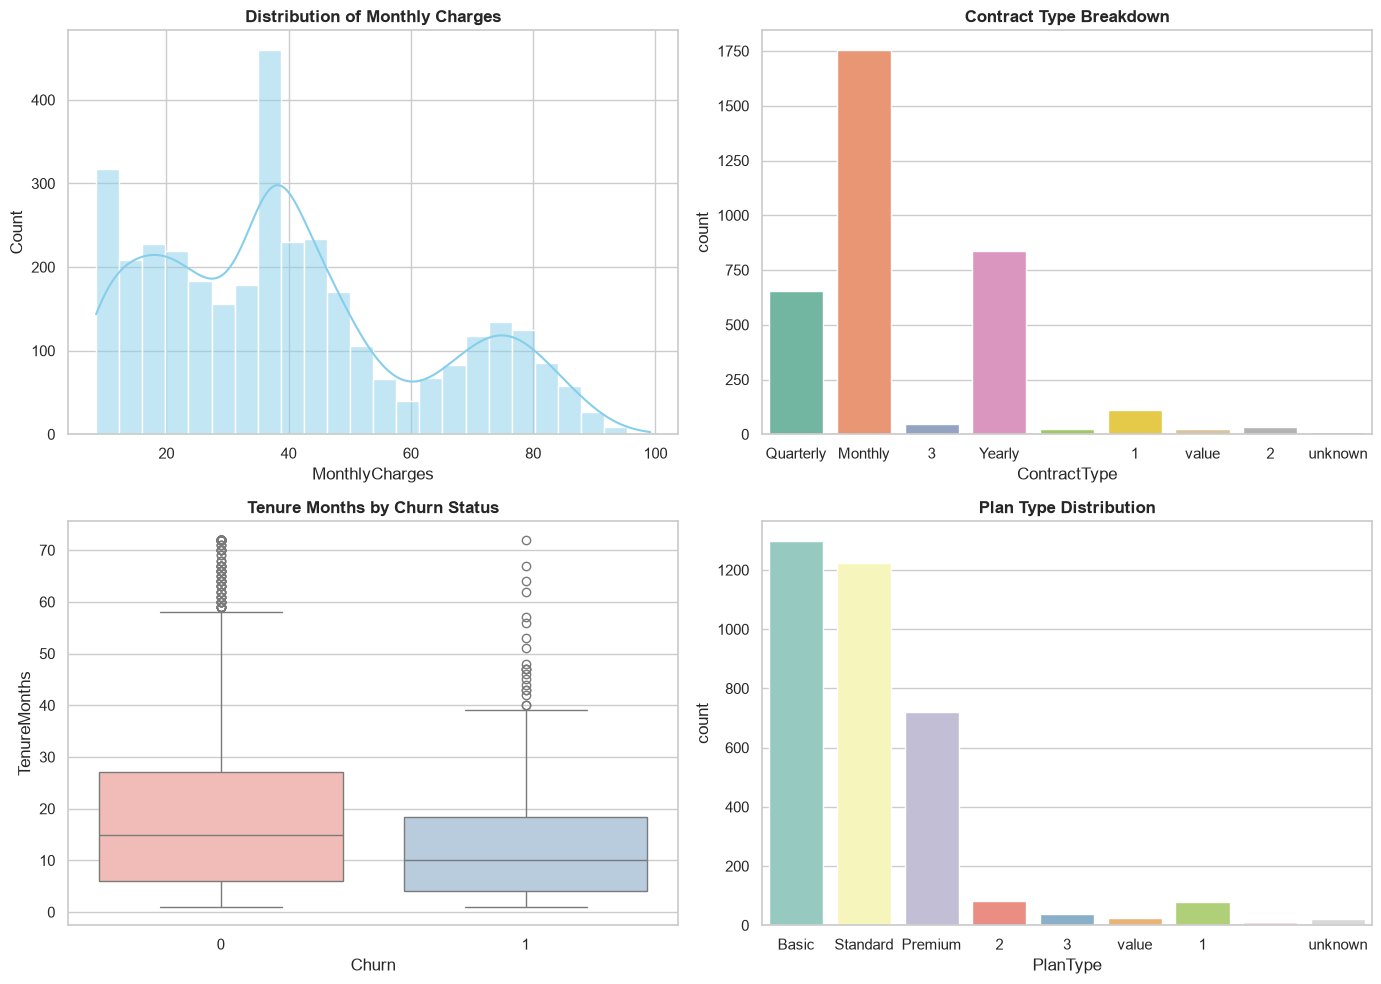

In [102]:
# AI code

# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))

# 1. Top-Left: Histogram of MonthlyCharges
sns.histplot(data=df, x='MonthlyCharges', kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Monthly Charges', fontsize=12, fontweight='bold')

# 2. Top-Right: Count plot of ContractType
sns.countplot(data=df, x='ContractType', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Contract Type Breakdown', fontsize=12, fontweight='bold')

# 3. Bottom-Left: Box plot of TenureMonths grouped by Churn
sns.boxplot(data=df, x='Churn', y='TenureMonths', ax=axes[1, 0], palette='Pastel1')
axes[1, 0].set_title('Tenure Months by Churn Status', fontsize=12, fontweight='bold')

# 4. Bottom-Right: Count plot of PlanType
sns.countplot(data=df, x='PlanType', ax=axes[1, 1], palette='Set3')
axes[1, 1].set_title('Plan Type Distribution', fontsize=12, fontweight='bold')

# Automatically adjust spacing so titles and labels don't overlap
plt.tight_layout()

# Display all charts together
plt.show()

In [105]:
# Define which columns contain these messy values
categorical_cols = ['ContractType', 'PlanType', 'Gender', 'Region', 'PaymentMethod', 'AutoPay']

# List the strings that represent garbage/missing values
garbage_values = ['1', '2', '3', 'value', 'unknown', 'N/A', '']

# Replace those specific strings with NaN across your categorical columns
df[categorical_cols] = df[categorical_cols].replace(garbage_values, np.nan)

df[categorical_cols] = df[categorical_cols].fillna(df[categorical_cols].mode())

C:\Users\Ebteshamul\AppData\Local\Temp\ipykernel_5508\2015222970.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='ContractType', ax=axes[0, 1], palette='Set2')
C:\Users\Ebteshamul\AppData\Local\Temp\ipykernel_5508\2015222970.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='TenureMonths', ax=axes[1, 0], palette='Pastel1')
C:\Users\Ebteshamul\AppData\Local\Temp\ipykernel_5508\2015222970.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='PlanType', ax=axes[1, 1], palette='Set3')


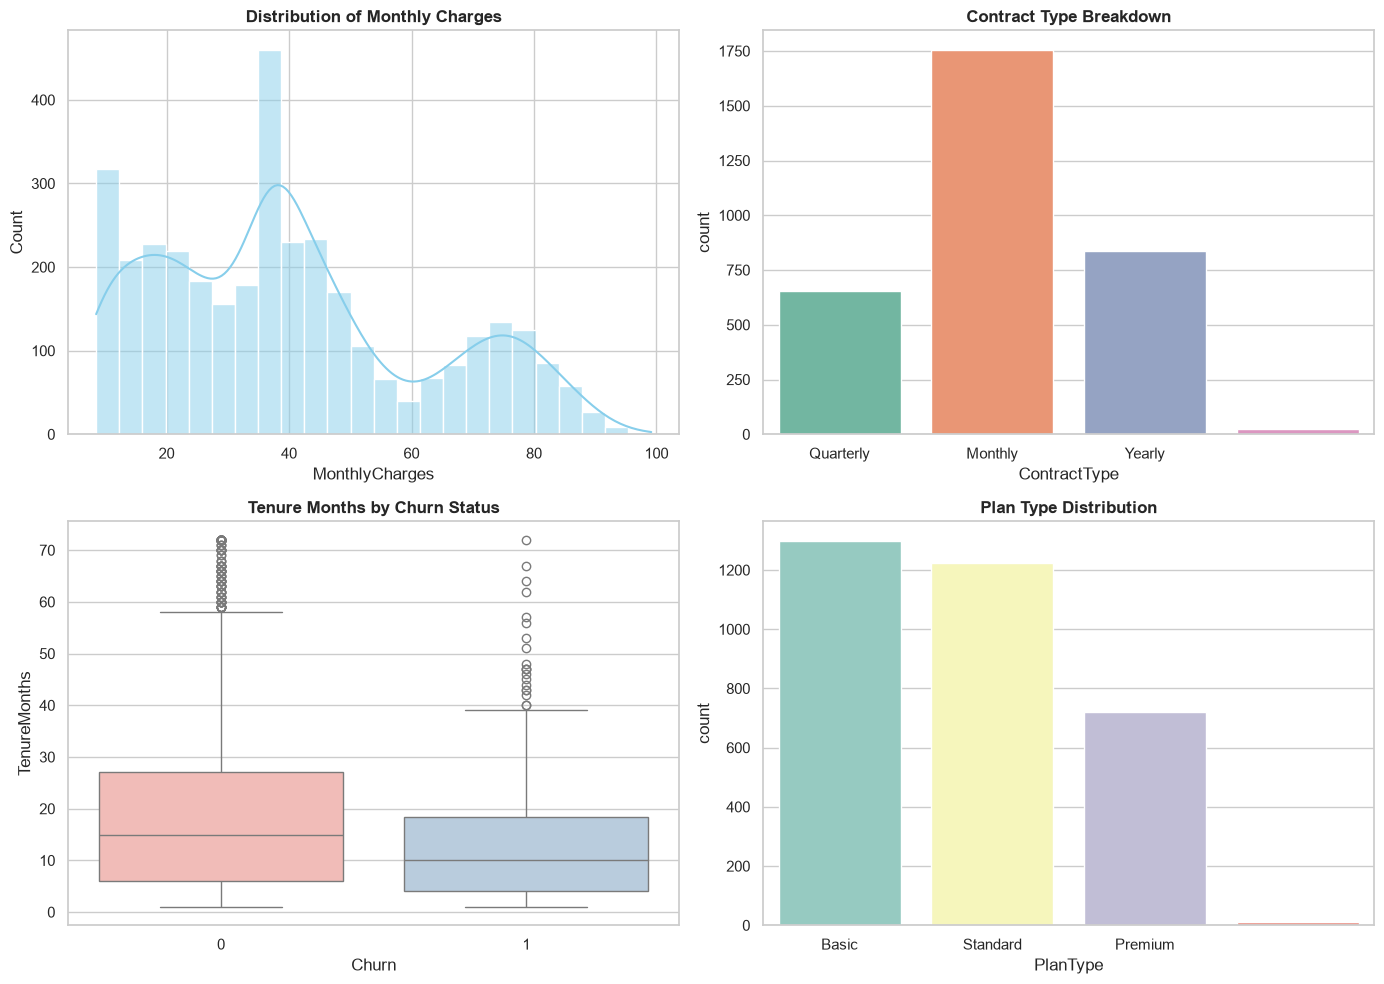

In [106]:
# AI code

# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))

# 1. Top-Left: Histogram of MonthlyCharges
sns.histplot(data=df, x='MonthlyCharges', kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribution of Monthly Charges', fontsize=12, fontweight='bold')

# 2. Top-Right: Count plot of ContractType
sns.countplot(data=df, x='ContractType', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Contract Type Breakdown', fontsize=12, fontweight='bold')

# 3. Bottom-Left: Box plot of TenureMonths grouped by Churn
sns.boxplot(data=df, x='Churn', y='TenureMonths', ax=axes[1, 0], palette='Pastel1')
axes[1, 0].set_title('Tenure Months by Churn Status', fontsize=12, fontweight='bold')

# 4. Bottom-Right: Count plot of PlanType
sns.countplot(data=df, x='PlanType', ax=axes[1, 1], palette='Set3')
axes[1, 1].set_title('Plan Type Distribution', fontsize=12, fontweight='bold')

# Automatically adjust spacing so titles and labels don't overlap
plt.tight_layout()

# Display all charts together
plt.show()

In [ ]:
fadsfgdfsa